In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics.pairwise import cosine_similarity

from sentence_transformers import SentenceTransformer


import gc
import torch


device = "cuda:1" if torch.cuda.is_available() else "cpu"
import gc


/export/home/stakir/.conda/envs/cuda_env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
df=pd.read_excel("verbal_reports_for12.xlsx",sheet_name="cleanversion2")


df
type_of_data="cleanversion2"
number_of_study= 12

if number_of_study==12 or number_of_study==6:
   df = df.drop(columns=['Study3', 'Study7', 'Study9'])


In [ ]:
if number_of_study == 12:
   
   if type_of_data == "cleanversion2":
      sheet_name = "Sheet4"
   elif type_of_data == "cleanversion1":
      sheet_name = f"high-lowconfidence_cleanversion" 
   else:
      sheet_name = f"high-lowconfidence_rawdata" 
   df_high_low=pd.read_excel("sentence_with_new_cleanversion.xlsx", sheet_name=sheet_name)
   df = pd.concat([df, df_high_low], axis=1)

df


In [4]:
if number_of_study == 12:
    target_sentences = ["Feared animal", "Grating orientation", "High face preference","Low face preference","Dog", "Red and high confidence","Red","High pain", "Low pain", "Red and green","High confidence", "Low confidence"] 
    target_to_label = {
                        "Feared animal": 0,
                        "Grating orientation": 1,
                        "High face preference": 2,
                        "Low face preference": 3,
                        "Dog": 4,
                        "Red and high confidence": 5,
                        "Red": 6,
                        "High pain": 7,
                        "Low pain": 8,
                        "Red and green": 9,
                        "High confidence": 10,
                        "Low confidence": 11
                    }
elif number_of_study == 6:
    target_sentences = ["Feared animal", "Grating orientation", "Dog", "Red and high confidence","Red", "Red and green"] 
    target_to_label ={
                        "Feared animal":0,
                        "Grating orientation":1, 
                        "Dog":2, 
                        "Red and high confidence":3,
                        "Red":4,
                        "Red and green":5}
elif number_of_study == 9:
    target_sentences = ["Feared animal", "Grating orientation", "Face preference","Dog", "Red and high confidence","Red","Pain", "Red and green","Confidence"] 
    target_to_label ={
                        "Feared animal":0,
                        "Grating orientation":1, 
                        "Face preference":2,
                        "Dog":3, 
                        "Red and high confidence":4,
                        "Red":5,
                        "Pain":6, 
                        "Red and green":7,
                        "Confidence":8}
  

In [5]:
# Study kolonlarını seç
study_cols = [col for col in df.columns if "Study" in col]

# Wide -> Long formata dönüştür
df_long = df.melt(value_vars=study_cols, var_name="study", value_name="text")
 
# Label ekle (Study1 → 0, Study2 → 1, ...)
df_long["label"] = df_long["study"].str.extract(r'(\d+)').astype(int) - 1

# NaN olan textleri düşür
df_long = df_long.dropna(subset=["text"]).reset_index(drop=True)


print(df_long.groupby(["study"]).sum())
print(df_long.shape)

                                                                   text  label
study                                                                         
Study1                Making the circle in 3D in mind. Concentrating...      0
Study2                Remembering various scenes from a famous anima...      9
Study3HighPreference  Focusing attention on the fixation point at th...     22
Study3LowPreference   Relaxing myself.Remembering various characters...     20
Study4                Mental humming Rosalia’s song: “think about yo...     54
Study5                Imagining live rock music, playing sports, doi...     60
Study6                Concentrating on the fixation point and attend...     60
Study7DownRegulation  Recalling positive and strong memories, deep, ...     30
Study7UpRegulation    Focusing on the screen and mentally describing...     24
Study8                Mentally doing math I just learnt in school. F...    119
Study9HighConfidence  Thinking of a scenery or perso

In [6]:

import re
# === 5. Nokta ekle (eğer yoksa) ===
df_long["text"] = df_long["text"].apply(
    lambda x: re.sub(r'(^|[.!?]\s+)([a-z])',
                     lambda m: m.group(1) + m.group(2).upper(),
                     x)
)
df_long["text"] = df_long["text"].apply(
    lambda t: t.strip() + "." if not t.strip().endswith(".") else t.strip()
)


In [7]:
df_long

,study,text,label
0,Study1,Making the circle in 3D in mind. Concentrating...,0
1,Study1,Imagining arrows shooting at the center of the...,0
2,Study1,"Imagining songs, petting a cat, various sport ...",0
3,Study1,Concentrating on the green circle and thinking...,0
4,Study1,"Imagining singing a song in head, driving a ca...",0
...,...,...,...
133,Study9LowConfidence,Gazing and focusing at the screen.,8
134,Study9LowConfidence,"Thinking about random thoughts,thinking hard a...",8
135,Study9LowConfidence,Imagining to be looking at many different dire...,8
136,Study9LowConfidence,Thinking about classes and tasks at university...,8


In [8]:
models_to_try = [
    
    "stsb-roberta-large",
    "all-mpnet-base-v2",
    "sentence-t5-xl",
    "gtr-t5-large",
    "all-roberta-large-v1",
    'sentence-t5-xxl',
    'gtr-t5-xxl',
    "all-mpnet-base-v1",
    "all-MiniLM-L6-v2",
    "all-MiniLM-L12-v1",
    "multi-qa-mpnet-base-dot-v1"

]

In [ ]:

# Dictionary to store sim_matrix for each model
sim_matrices = {}

all_rows = []
# ============================
# 1) Compute similarity matrices for each model
# ============================
for model_name in models_to_try:
    print(f"--- Model: {model_name} ---")

    model = SentenceTransformer(model_name, device=device)

    # Compute embeddings
    embeddings = model.encode(df_long["text"].tolist(), convert_to_numpy=True, show_progress_bar=False)
    target_embeddings = model.encode(target_sentences, convert_to_numpy=True, show_progress_bar=False)
    print(target_embeddings.shape, embeddings.shape)

    # Cosine similarity matrix
    sim_matrix = cosine_similarity(target_embeddings, embeddings)
    print(sim_matrix.shape)
    

    # SAVE IT IN DICTIONARY
    sim_matrices[model_name] = sim_matrix

    del model
    del embeddings
    del target_embeddings
    torch.cuda.empty_cache()  # GPU belleğini boşalt (varsa)
    gc.collect()              # CPU RAM temizliği

--- Model: stsb-roberta-large ---


Loading weights: 100%|██████████| 391/391 [00:00<00:00, 11818.77it/s]


(12, 1024) (138, 1024)
(12, 138)
--- Model: all-mpnet-base-v2 ---


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 8951.14it/s]


(12, 768) (138, 768)
(12, 138)
--- Model: sentence-t5-xl ---


Loading weights: 100%|██████████| 195/195 [00:00<00:00, 2051.88it/s]


... (13 outputs left out)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 9062.12it/s]


(12, 384) (138, 384)
(12, 138)
--- Model: multi-qa-mpnet-base-dot-v1 ---


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 8789.85it/s]


(12, 768) (138, 768)
(12, 138)


                 Model    Type  Correlation       Sentence
0   stsb-roberta-large  Within     0.137049  Feared animal
1   stsb-roberta-large  Within     0.251965  Feared animal
2   stsb-roberta-large  Within    -0.006777  Feared animal
3   stsb-roberta-large  Within     0.062273  Feared animal
4   stsb-roberta-large  Within    -0.029075  Feared animal
5   stsb-roberta-large  Within     0.084954  Feared animal
6   stsb-roberta-large  Within    -0.003232  Feared animal
7   stsb-roberta-large  Within     0.101778  Feared animal
8   stsb-roberta-large  Within    -0.002213  Feared animal
9   stsb-roberta-large  Within     0.016676  Feared animal
10  stsb-roberta-large  Within     0.287908  Feared animal
11  stsb-roberta-large  Within     0.003281  Feared animal
12  stsb-roberta-large  Within     0.089066  Feared animal
13  stsb-roberta-large  Within    -0.024789  Feared animal
14  stsb-roberta-large  Within     0.220155  Feared animal
15  stsb-roberta-large  Within     0.043121  Feared anim

/scratch/stakir/ipykernel_1818898/2208368254.py:47: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(


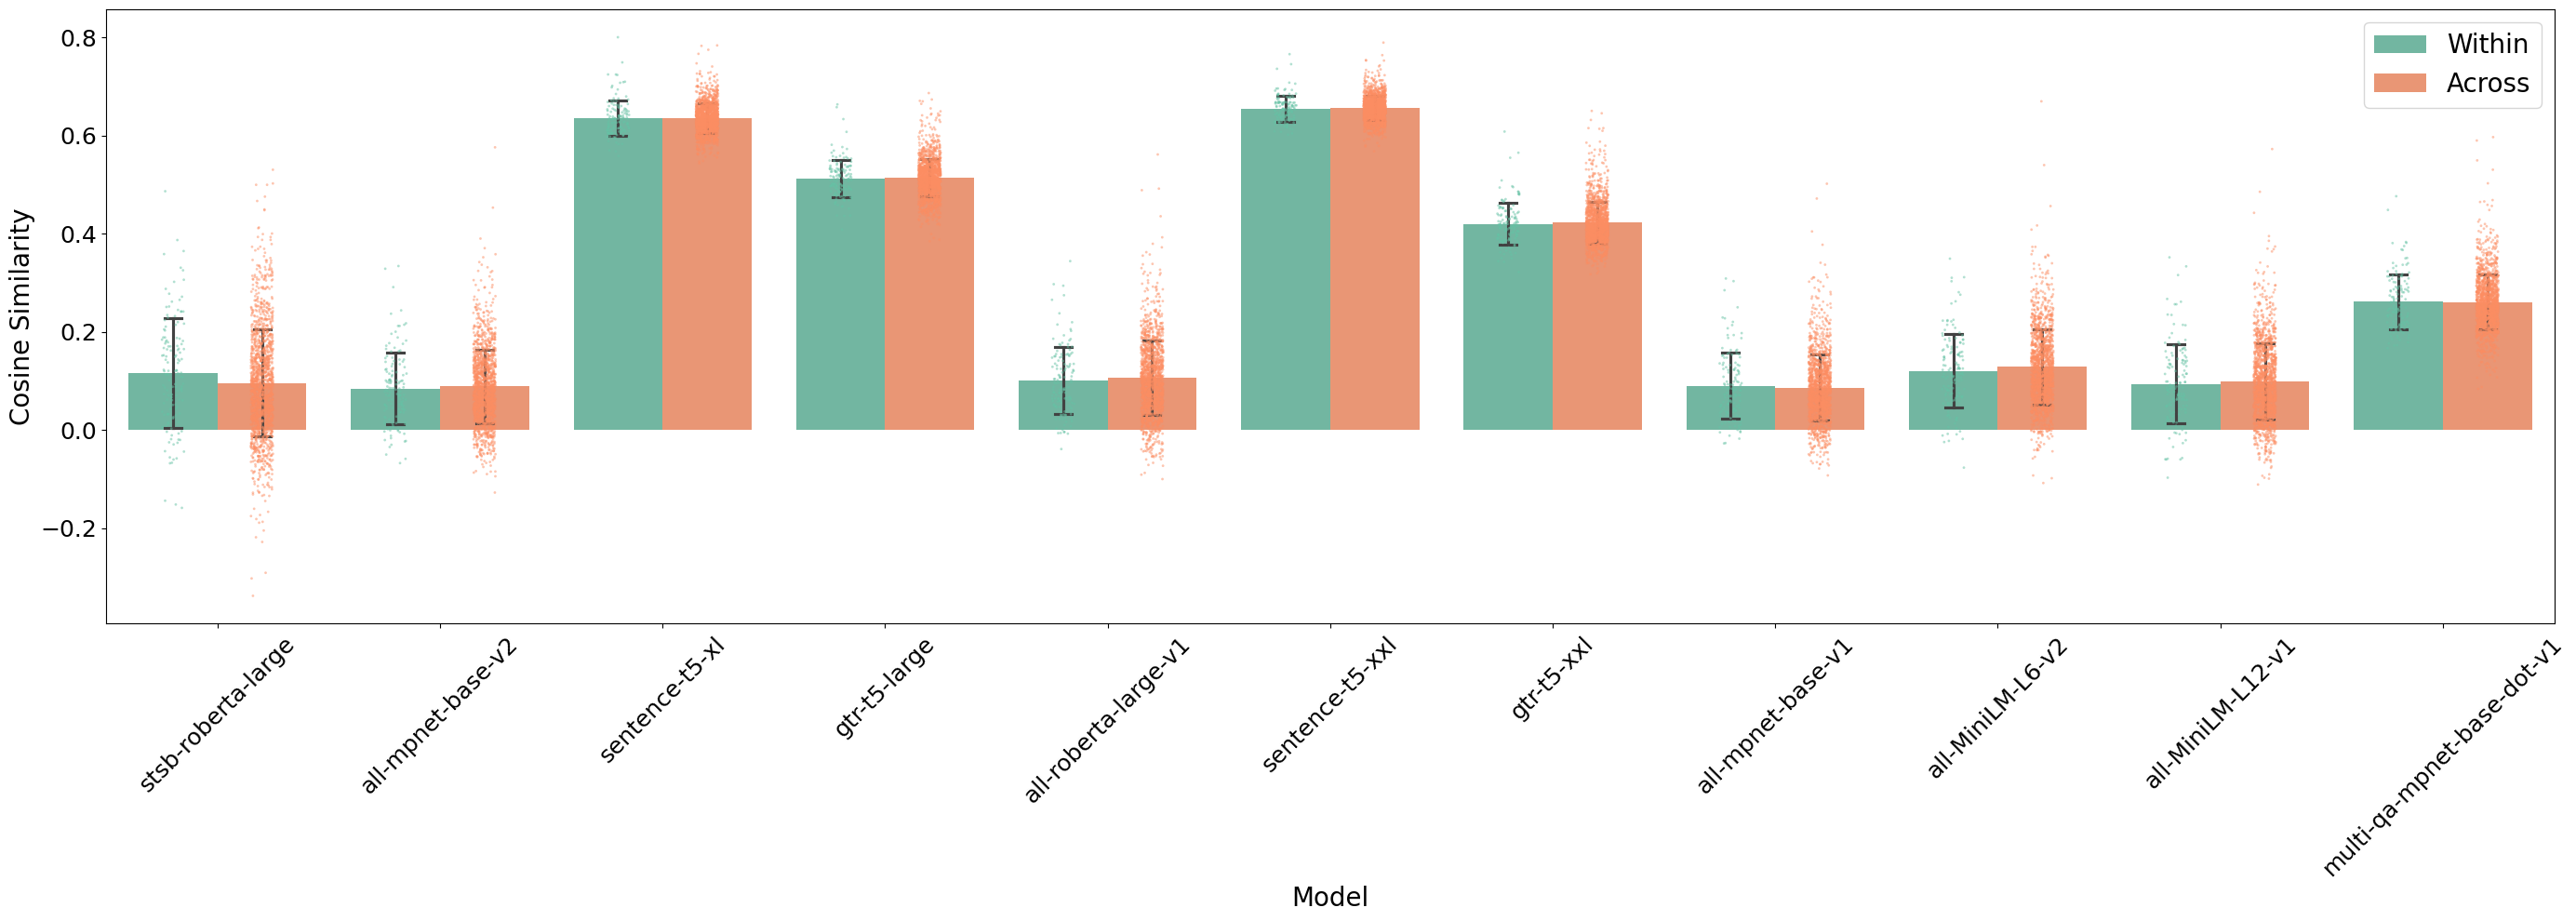

In [10]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity

# ============================
# Extract Within / Off correlations for all models
# ============================
for model_name, sim_matrix in sim_matrices.items():

    sim_df = pd.DataFrame(sim_matrix, index=target_sentences, columns=df_long["label"])
    

    for target_label in sim_df.index:


        target_label_id = target_to_label[target_label]

        for col_label in sim_df.columns.unique():

            values = sim_df.loc[target_label, sim_df.columns == col_label].values

            if target_label_id == col_label:
                for v in values:
                    all_rows.append([model_name, "Within", v, target_label])
            else:
                for v in values:
                    all_rows.append([model_name, "Across", v, target_label])

# Combined dataframe
df_all = pd.DataFrame(all_rows, columns=["Model", "Type", "Correlation", "Sentence"])
print(df_all.head(25))
# ============================
# Save per-model Within/Cross means
# ============================
mean_df = df_all.groupby(["Model", "Type"])["Correlation"].mean().reset_index()
#mean_df.to_csv(f"similarty_csv/{type_of_data}_data_within_off_means_per_model_{number_of_study}.csv", index=False)

print(f"Saved: similarty_csv/{type_of_data}_data_within_off_means_per_model_{number_of_study}.csv")
print(mean_df)

# ============================
# Plot
# ============================
plt.figure(figsize=(28, 10))

sns.barplot(
    data=df_all,
    x="Model",
    y="Correlation",
    hue="Type",
    ci="sd",
    capsize=0.15,
    palette="Set2"
)

sns.stripplot(
    data=df_all,
    x="Model",
    y="Correlation",
    hue="Type",
    dodge=True,
    size=2,
    alpha=0.5,
    palette="Set2"
)

handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(handles[:2], labels[:2], fontsize=20)

plt.xlabel("Model",fontsize=20)
plt.ylabel("Cosine Similarity", fontsize=20)
plt.yticks(fontsize=18)
plt.xticks(rotation=45, fontsize=18)
plt.tight_layout()
plt.show()

